In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Dict, List, Optional, Tuple
from pathlib import Path
import os
from glob import glob

import h5py
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
import sys
import h5py
# Add src to path for custom utilities
sys.path.insert(0, f'/home/obandohe/JIPSENSE/JIPSENSE')
from src.utils.seismic_io import load_traces_from_hdf5, print_hdf5_info
from src.utils.fk_spectrum_class import FKSpectrum
from src.utils.Preprocessing_SW import agc_gain, Array_to_ObsPy
import src.utils.wft as wft

print("✓ All libraries imported successfully")

✓ All libraries imported successfully


In [2]:
def getSpectrum(data_mod,fs,dx,fmin,fmax,vel_min,vel_max):
    ''' Function to compute the wavefield transform of a given data set
    Parameters:
    data_mod: data to be transformed
    fs: sampling frequency in Hz
    dx: receiver spacing in meters
    fmin: minimum frequency in Hz
    fmax: maximum frequency in Hz
    vel_min: minimum velocity in m/s
    vel_max: maximum velocity in m/s

    returns:
    power: power spectrum 
    power_norm: normalized power spectrum
    frequencies: frequencies
    velocities: velocities

    '''
    # receiver coordinates
    offsets = np.arange(data_mod.shape[1])*dx
    # velocity range
    velocities = np.linspace(vel_min,vel_max,250)
    # parameters for the wavefield transform
    settings = {'fmin':fmin,'fmax':fmax,'fdbf_weighting':'sqrt','fdbf_steering':'cylindrical'}
    # normalize data
    data_norm = data_mod/np.max(np.abs(data_mod),axis=0)
    # perform wavefield transform
    tmatrix = np.transpose(data_norm)
    frequencies, power = wft.phase_shift(tmatrix, offsets, fs, velocities, settings)
    # normalize power spectrum
    power_norm = np.abs(power)/np.max(np.abs(power),axis=0)

    return np.abs(power), power_norm, frequencies, velocities


In [3]:

def read_trace_file(semp_file: Path) -> Tuple[np.ndarray, np.ndarray, float]:
    """
    Read a SPECFEM2D seismic trace file (.semp format).
    
    Format: Two columns separated by whitespace
    - Column 1: Time (seconds)
    - Column 2: Pressure/Amplitude
    
    Args:
        semp_file: Path to .semp file
        
    Returns:
        Tuple of (time array, pressure array, dt)
    """
    try:
        data = np.loadtxt(semp_file)
        
        if data.ndim == 1:
            # Single sample (unlikely, but handle it)
            time = np.array([data[0]])
            pressure = np.array([data[1]])
        else:
            time = data[:, 0]
            pressure = data[:, 1]
        
        # Compute dt from time differences
        if len(time) > 1:
            dt = float(np.mean(np.diff(time)))
        else:
            dt = 1.0  # Default if only one sample
        
        return time, pressure, dt
    
    except Exception as e:
        print(f"Error reading {semp_file}: {e}")
        return None, None, None



def save_data_mod_to_h5(data_mod, fs, station_coords, params, filename):
    with h5py.File(filename, "w") as f:
        f.create_dataset("data", data=data_mod)
        f.create_dataset("fs", data=fs)
        f.create_dataset("receiver_coordinates", data=station_coords)
        f.create_dataset("params", data=str(params))
    print(f"Data saved to {filename}")

Processing signal_type=PRE.semp, source_type=wh
Data saved to /mnt/p/11212604-jip-sense/DAS/SPECFEM2D_OUTPUTS/JAPANESE_SOIL_CONDITIONS/hdf5_files_JAP/simulation_inclined_JAP_pressure_wh.h5
Saved HDF5 file for PRE.semp


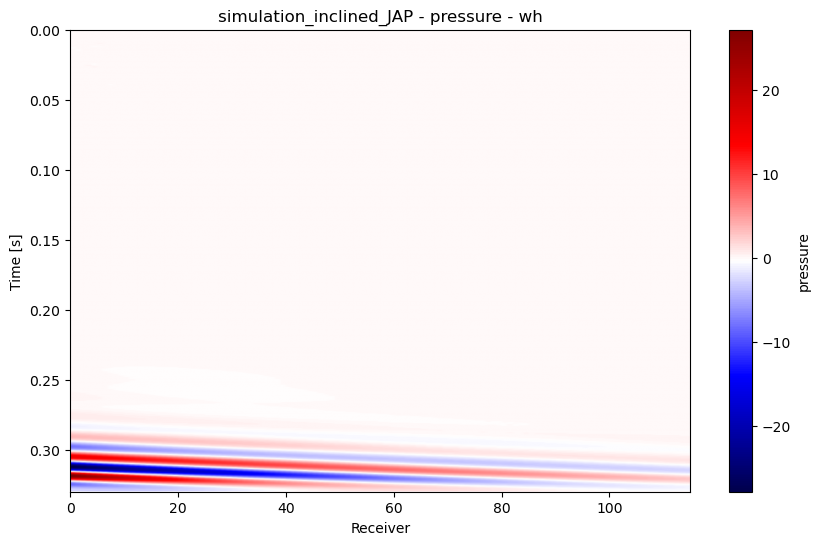

Processing signal_type=PRE.semp, source_type=tr
Data saved to /mnt/p/11212604-jip-sense/DAS/SPECFEM2D_OUTPUTS/JAPANESE_SOIL_CONDITIONS/hdf5_files_JAP/simulation_inclined_JAP_pressure_tr.h5
Saved HDF5 file for PRE.semp


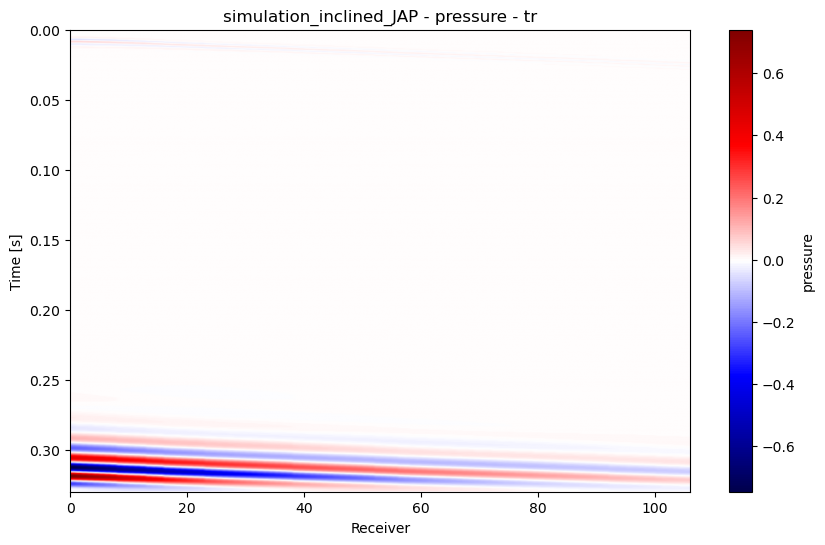

In [4]:
# read STATIONS
rooth_path = f'/mnt/p/11212604-jip-sense/DAS/SPECFEM2D_OUTPUTS/JAPANESE_SOIL_CONDITIONS'
os.chdir(rooth_path)

model_name = 'simulation_inclined_JAP'

for signal_type in ['PRE.semp']:  # or 'FXX.semv' or 'FXZ.semv'

    for source_type in ['wh', 'tr']:

        print(f"Processing signal_type={signal_type}, source_type={source_type}")

        if signal_type=='PRE.semp':
            signal_suffix = 'pressure'
        elif signal_type=='FXX.semv':
            signal_suffix = 'VXX'
        elif signal_type=='FXZ.semv':
            signal_suffix = 'VXZ'
        else:
            raise ValueError(f"Unsupported signal type: {signal_type}")

        stations = np.genfromtxt(f'{rooth_path}/{model_name}/DATA/STATIONS')

        coord_x = stations[:,2]
        coord_y = stations[:,3]

        # get folders from the model output directory
        output_folders = glob(f'{rooth_path}/{model_name}/RESULTS/*')

        # select folder name that ends witn _wh
        output_folder = [folder for folder in output_folders if folder.endswith(f'_{source_type}')][0]

        files = sorted(glob(f'{output_folder}/*.{signal_type}'))

        #print(files)

        all_traces = []

        for file in files:
            time,trace,dt = read_trace_file(file)
            all_traces.append(trace)

        all_traces =  np.array(all_traces).T

        # Convert all_traces to obspy 
        st = Array_to_ObsPy(all_traces,1/dt)

        # preprocess data
        st_filt = st.copy()
        st_filt.taper(max_percentage=0.05, type='hann')

        fmin = 10.0
        fmax = 800.0
        filter_order = 5

        st_filt.filter('bandpass', freqmin=fmin, freqmax=fmax, corners=filter_order, zerophase=True)

        fs = 2000

        # resample to 1000 Hz
        st_filt.resample(fs)

        # convert to numpy array
        data_mod = np.array([tr.data for tr in st_filt.traces]).T
        time = np.arange(data_mod.shape[0])/fs

        params = {'Filtered signal': True,
                'fmin [Hz]': fmin, 
                'fmax [Hz]': fmax, 
                'filter_order': filter_order, 
                'original_fs [Hz]': 1/dt,
                'resampled_fs [Hz]': fs,
                'receiver_spacing [m]': np.mean(np.diff(coord_x))
                }

        #write a function to save data_mod to a h5 file. Include fs,station coordinates

        # example usage
        station_coords = np.column_stack((coord_x, coord_y))
        save_data_mod_to_h5(data_mod, fs, station_coords, params, f"{rooth_path}/hdf5_files_JAP/{model_name}_{signal_suffix}_{source_type}.h5")

        print(f"Saved HDF5 file for {signal_type}")


        # plot data_mod
        import matplotlib.pyplot as plt

        plt.figure(figsize=(10, 6))
        plt.imshow(data_mod, aspect='auto', cmap='seismic', extent=[0, data_mod.shape[1], time[-1], time[0]])
        plt.colorbar(label=signal_suffix)
        plt.xlabel('Receiver')
        plt.ylabel('Time [s]')
        plt.title(f'{model_name} - {signal_suffix} - {source_type}')

        # save the figure as a PNG file
        plt.savefig(f"{rooth_path}/hdf5_files_JAP/{model_name}_{signal_suffix}_{source_type}.png")

        plt.show()


In [ ]:
# test saving and loading the h5 file
filename = f"/mnt/p/11212604-jip-sense/DAS/SPECFEM2D_OUTPUTS/JAPANESE_SOIL_CONDITIONS/hdf5_files/{model_name}_{signal_suffix}_{source_type}.h5"
with h5py.File(filename, "r") as f:
    data_loaded = f["data"][:]
    fs_loaded = f["fs"][()]
    station_coords_loaded = f["receiver_coordinates"][:]
    params_loaded = f["params"][()].decode("utf-8")

print(f"Data shape: {data_loaded.shape}")
print(f"Sampling frequency: {fs_loaded}")
print(f"Station coordinates shape: {station_coords_loaded.shape}")
print(f"Params: {params_loaded}")

In [ ]:
station_coords